# 3 · Clustering

Can the clips be grouped by language **without labels**? Four algorithms are applied to one vector per file
(the mean of its 10 s segment features, original audio only):

* **K-Means** – centroid-based, assumes compact spherical clusters
* **Agglomerative (Ward)** – hierarchical, no initialisation randomness, gives a dendrogram
* **Gaussian Mixture Model** – soft, elliptical clusters, model selection with BIC
* **DBSCAN** – density-based, finds an arbitrary number of clusters and marks outliers

The number of clusters is chosen with the elbow method, silhouette score and BIC, then compared with the true number of
languages (4). Clusters are compared to **language**, **gender** and estimated **narrator** labels to see what the feature space
actually organises around.

In [1]:
%load_ext autoreload
%autoreload 2
import os, warnings; warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from slid import config as C, features, clustering, plotting
plotting.setup(); RS = C.RANDOM_STATE

meta = pd.read_parquet(C.PROCESSED_DIR / "metadata.parquet").set_index("file_id")
seg = pd.read_parquet(C.PROCESSED_DIR / "segment_features.parquet")
FEATS = features.feature_columns(seg.columns)
F = clustering.file_level_matrix(seg, FEATS)
meta = meta.loc[F.index]
refs = {"language": meta.label.to_numpy(), "gender": meta.gender.to_numpy(), "narrator": meta.narrator.to_numpy()}
print(F.shape)

(719, 381)


## 3.1 Feature space for clustering

Standardise, then PCA to 95 % of the variance. Distance-based clustering suffers in 381 correlated dimensions; PCA removes
redundancy and noise while keeping almost all information.

In [2]:
Z = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(F))
pca = PCA(n_components=0.95, random_state=RS).fit(Z)
X = pca.transform(Z)
print(f"{X.shape[1]} PCA components keep 95% of the variance")

78 PCA components keep 95% of the variance


## 3.2 Choosing the number of clusters

elbow: 12 | best silhouette: {'kmeans': 15, 'agglo': 16, 'gmm': 15} | min BIC: 10


,kmeans_inertia,kmeans_silhouette,agglo_silhouette,gmm_silhouette,gmm_bic
k,,,,,
2,211290.227,0.180,0.183,0.164,189217.577
3,182807.017,0.180,0.169,0.155,188796.471
4,161716.008,0.206,0.201,0.138,187986.600
5,149074.445,0.201,0.223,0.174,187398.652
6,136819.976,0.218,0.213,0.184,187241.759
7,127039.201,0.235,0.231,0.209,187106.002
8,119267.642,0.246,0.247,0.228,186582.051
9,111281.938,0.266,0.264,0.240,186558.620
10,105315.812,0.269,0.268,0.245,186060.713


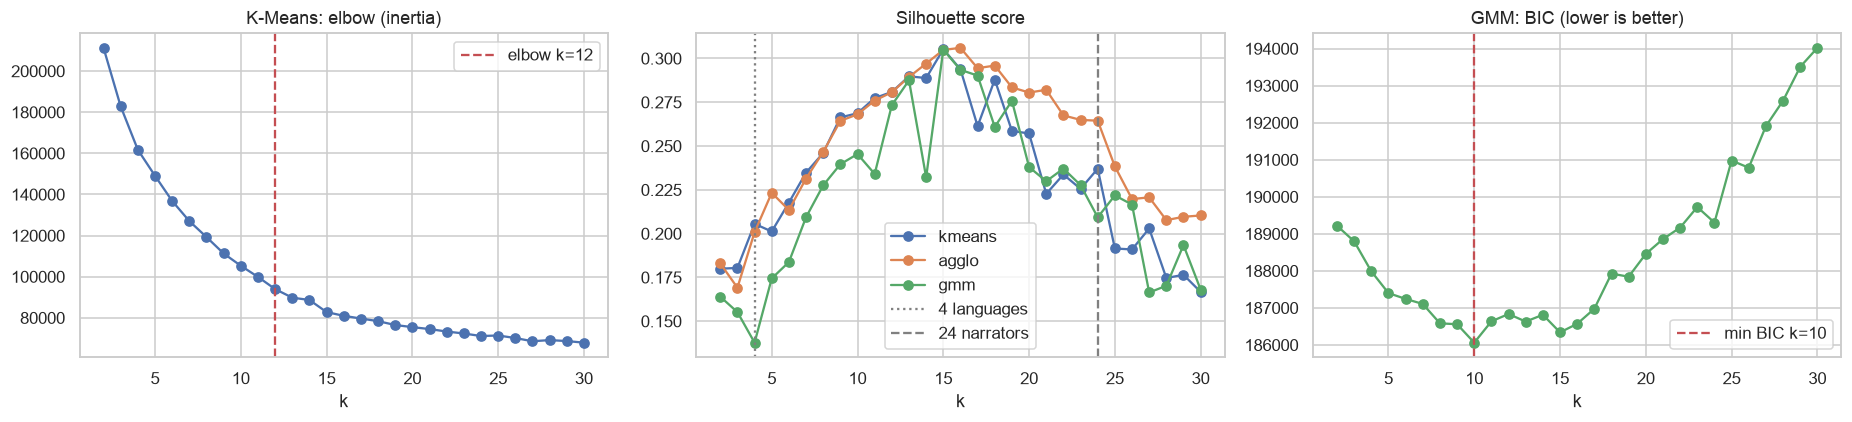

In [3]:
ks = range(2, 31)
rows = []
for k in ks:
    km = KMeans(k, n_init=20, random_state=RS).fit(X)
    ag = AgglomerativeClustering(k, linkage="ward").fit(X)
    gm = GaussianMixture(k, covariance_type="diag", n_init=5, random_state=RS).fit(X)
    rows.append({"k": k, "kmeans_inertia": km.inertia_,
                 "kmeans_silhouette": silhouette_score(X, km.labels_),
                 "agglo_silhouette": silhouette_score(X, ag.labels_),
                 "gmm_silhouette": silhouette_score(X, gm.predict(X)),
                 "gmm_bic": gm.bic(X)})
sel = pd.DataFrame(rows).set_index("k")

# elbow = point with the largest distance to the line joining the first and last inertia values
x, y = np.array(ks, float), sel.kmeans_inertia.to_numpy()
xn, yn = (x - x[0]) / (x[-1] - x[0]), (y - y[-1]) / (y[0] - y[-1])
elbow_k = int(x[np.argmax(np.abs(xn + yn - 1))])
best_sil = {m: int(sel[f"{m}_silhouette"].idxmax()) for m in ["kmeans", "agglo", "gmm"]}
best_bic = int(sel.gmm_bic.idxmin())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(sel.index, sel.kmeans_inertia, "o-"); axes[0].axvline(elbow_k, ls="--", c="C3", label=f"elbow k={elbow_k}")
axes[0].set_title("K-Means: elbow (inertia)"); axes[0].legend()
for m in ["kmeans", "agglo", "gmm"]:
    axes[1].plot(sel.index, sel[f"{m}_silhouette"], "o-", label=m)
axes[1].axvline(4, ls=":", c="gray", label="4 languages"); axes[1].axvline(24, ls="--", c="gray", label="24 narrators"); axes[1].set_title("Silhouette score"); axes[1].legend()
axes[2].plot(sel.index, sel.gmm_bic, "o-", c="C2"); axes[2].axvline(best_bic, ls="--", c="C3", label=f"min BIC k={best_bic}")
axes[2].set_title("GMM: BIC (lower is better)"); axes[2].legend()
for ax in axes: ax.set_xlabel("k")
plt.tight_layout(); plotting.save(fig, "03_choosing_k")
print("elbow:", elbow_k, "| best silhouette:", best_sil, "| min BIC:", best_bic)
sel.round(3)

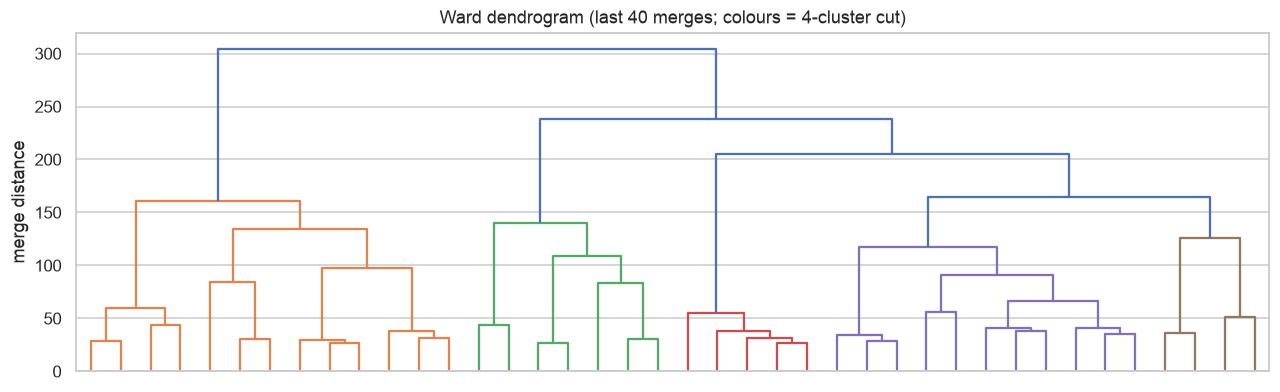

In [4]:
Lw = linkage(X, method="ward")
fig, ax = plt.subplots(figsize=(14, 4))
dendrogram(Lw, truncate_mode="lastp", p=40, ax=ax, color_threshold=Lw[-4, 2], no_labels=True)
ax.set_title("Ward dendrogram (last 40 merges; colours = 4-cluster cut)"); ax.set_ylabel("merge distance")
plotting.save(fig, "03_dendrogram")

**Does the optimal k match the number of languages? No.**

* The inertia curve has no sharp elbow; the knee heuristic gives k = 12 over the range 2–30.
* The silhouette score rises from ≈ 0.21 at k = 4 to a maximum of ≈ 0.31 at k = 15–16 for all three methods, then falls.
* GMM's BIC is lowest at k = 10.

All criteria point to 10–16 groups, between the 4 languages and the ~24 estimated narrators (several small narrator
groups are merged with similar voices). Silhouette values ≤ 0.31 also mean the groups overlap considerably. The natural
grouping of this feature space is by **voice / recording**, not by language.

## 3.3 Clustering results

Each algorithm is run with k = 4 (the number of languages) and with its own data-driven k. DBSCAN's `eps` is taken from the
knee of the 10-nearest-neighbour distance curve.

,n_clusters,noise_frac,silhouette,purity_language,ARI_language,NMI_language,purity_gender,ARI_gender,NMI_gender,purity_narrator,ARI_narrator,NMI_narrator
K-Means (k=4),4.0,0.00,0.206,0.581,0.279,0.384,0.823,0.279,0.343,0.389,0.313,0.618
K-Means (k=15),15.0,0.00,0.305,0.994,0.430,0.692,1.000,0.169,0.427,0.841,0.865,0.932
Agglomerative (k=4),4.0,0.00,0.201,0.581,0.282,0.389,0.805,0.250,0.324,0.389,0.322,0.632
Agglomerative (k=16),16.0,0.00,0.306,0.999,0.420,0.690,1.000,0.163,0.420,0.851,0.881,0.940
GMM (k=4),4.0,0.00,0.138,0.597,0.279,0.426,0.834,0.244,0.309,0.401,0.250,0.579
"GMM (k=10, BIC)",10.0,0.00,0.245,0.880,0.391,0.636,0.897,0.142,0.366,0.730,0.624,0.848
DBSCAN,14.0,0.05,0.293,0.889,0.380,0.630,0.950,0.181,0.414,0.782,0.811,0.916


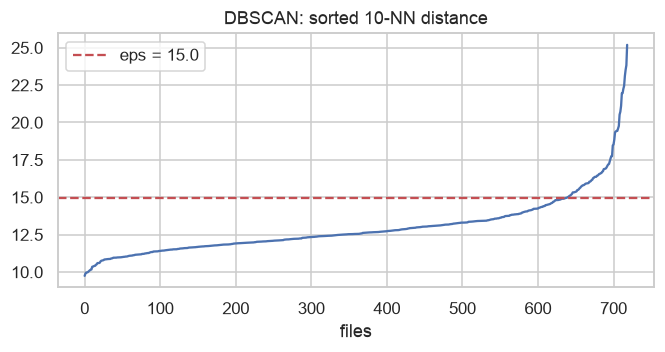

In [5]:
d10 = np.sort(NearestNeighbors(n_neighbors=10).fit(X).kneighbors(X)[0][:, -1])
xn = np.linspace(0, 1, len(d10)); yn = (d10 - d10[0]) / (d10[-1] - d10[0])
eps = float(d10[np.argmax(xn - yn)])
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(d10); ax.axhline(eps, ls="--", c="C3", label=f"eps = {eps:.1f}"); ax.legend()
ax.set_title("DBSCAN: sorted 10-NN distance"); ax.set_xlabel("files"); plotting.save(fig, "03_dbscan_kdist")

runs = {
    "K-Means (k=4)": KMeans(4, n_init=20, random_state=RS).fit_predict(X),
    f"K-Means (k={best_sil['kmeans']})": KMeans(best_sil["kmeans"], n_init=20, random_state=RS).fit_predict(X),
    "Agglomerative (k=4)": AgglomerativeClustering(4, linkage="ward").fit_predict(X),
    f"Agglomerative (k={best_sil['agglo']})": AgglomerativeClustering(best_sil["agglo"], linkage="ward").fit_predict(X),
    "GMM (k=4)": GaussianMixture(4, covariance_type="diag", n_init=5, random_state=RS).fit(X).predict(X),
    f"GMM (k={best_bic}, BIC)": GaussianMixture(best_bic, covariance_type="diag", n_init=5, random_state=RS).fit(X).predict(X),
    "DBSCAN": DBSCAN(eps=eps, min_samples=10).fit_predict(X),
}
res = pd.DataFrame({name: clustering.evaluate(X, lab, refs) for name, lab in runs.items()}).T
cols = ["n_clusters", "noise_frac", "silhouette", "purity_language", "ARI_language", "NMI_language",
        "purity_gender", "ARI_gender", "NMI_gender", "purity_narrator", "ARI_narrator", "NMI_narrator"]
res = res[cols].astype(float)
res.to_csv(C.RESULTS_DIR / "clustering_metrics.csv")
assign = pd.DataFrame(runs, index=F.index).join(meta[["language", "gender", "narrator", "split"]])
assign.to_csv(C.RESULTS_DIR / "cluster_assignments.csv")
res.round(3)

For reference: with 4 balanced languages, random clusters give a language purity of ≈ 0.25 and ARI ≈ 0;
for gender the purity baseline is 0.5.

## 3.4 Cluster composition

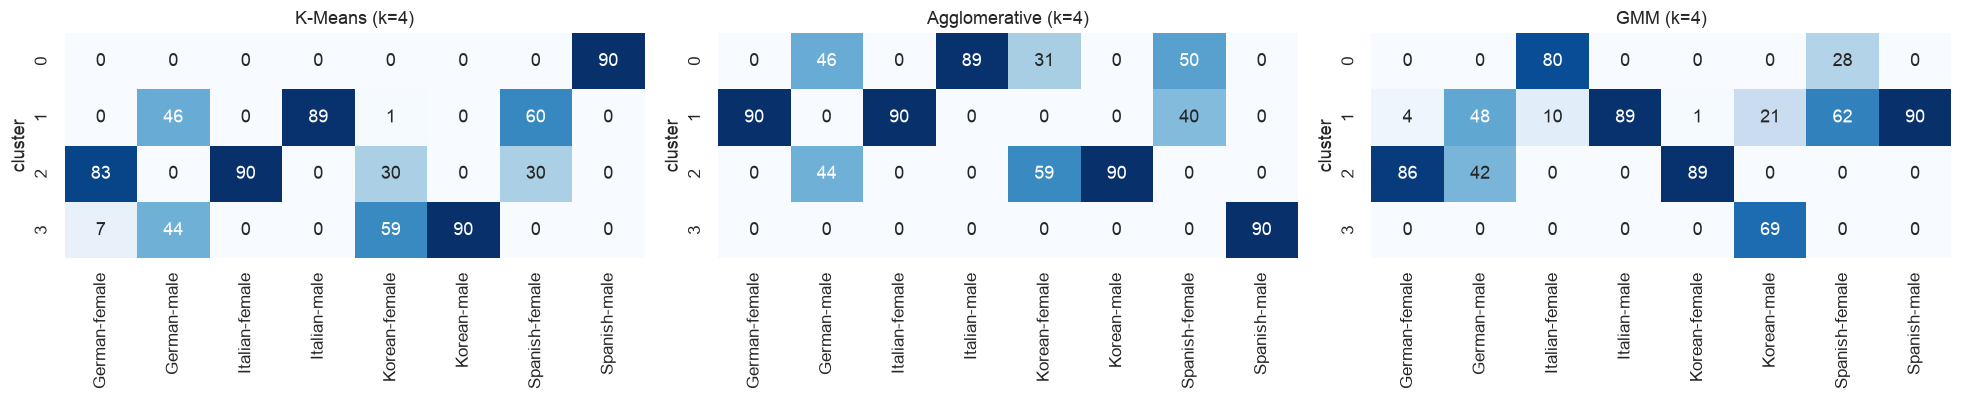

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
for ax, name in zip(axes, ["K-Means (k=4)", "Agglomerative (k=4)", "GMM (k=4)"]):
    ct = pd.crosstab(assign[name], [assign.language, assign.gender])
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name); ax.set_ylabel("cluster"); ax.set_xlabel("")
plt.tight_layout(); plotting.save(fig, "03_cluster_composition")

## 3.5 2-D visualisation (PCA and t-SNE)

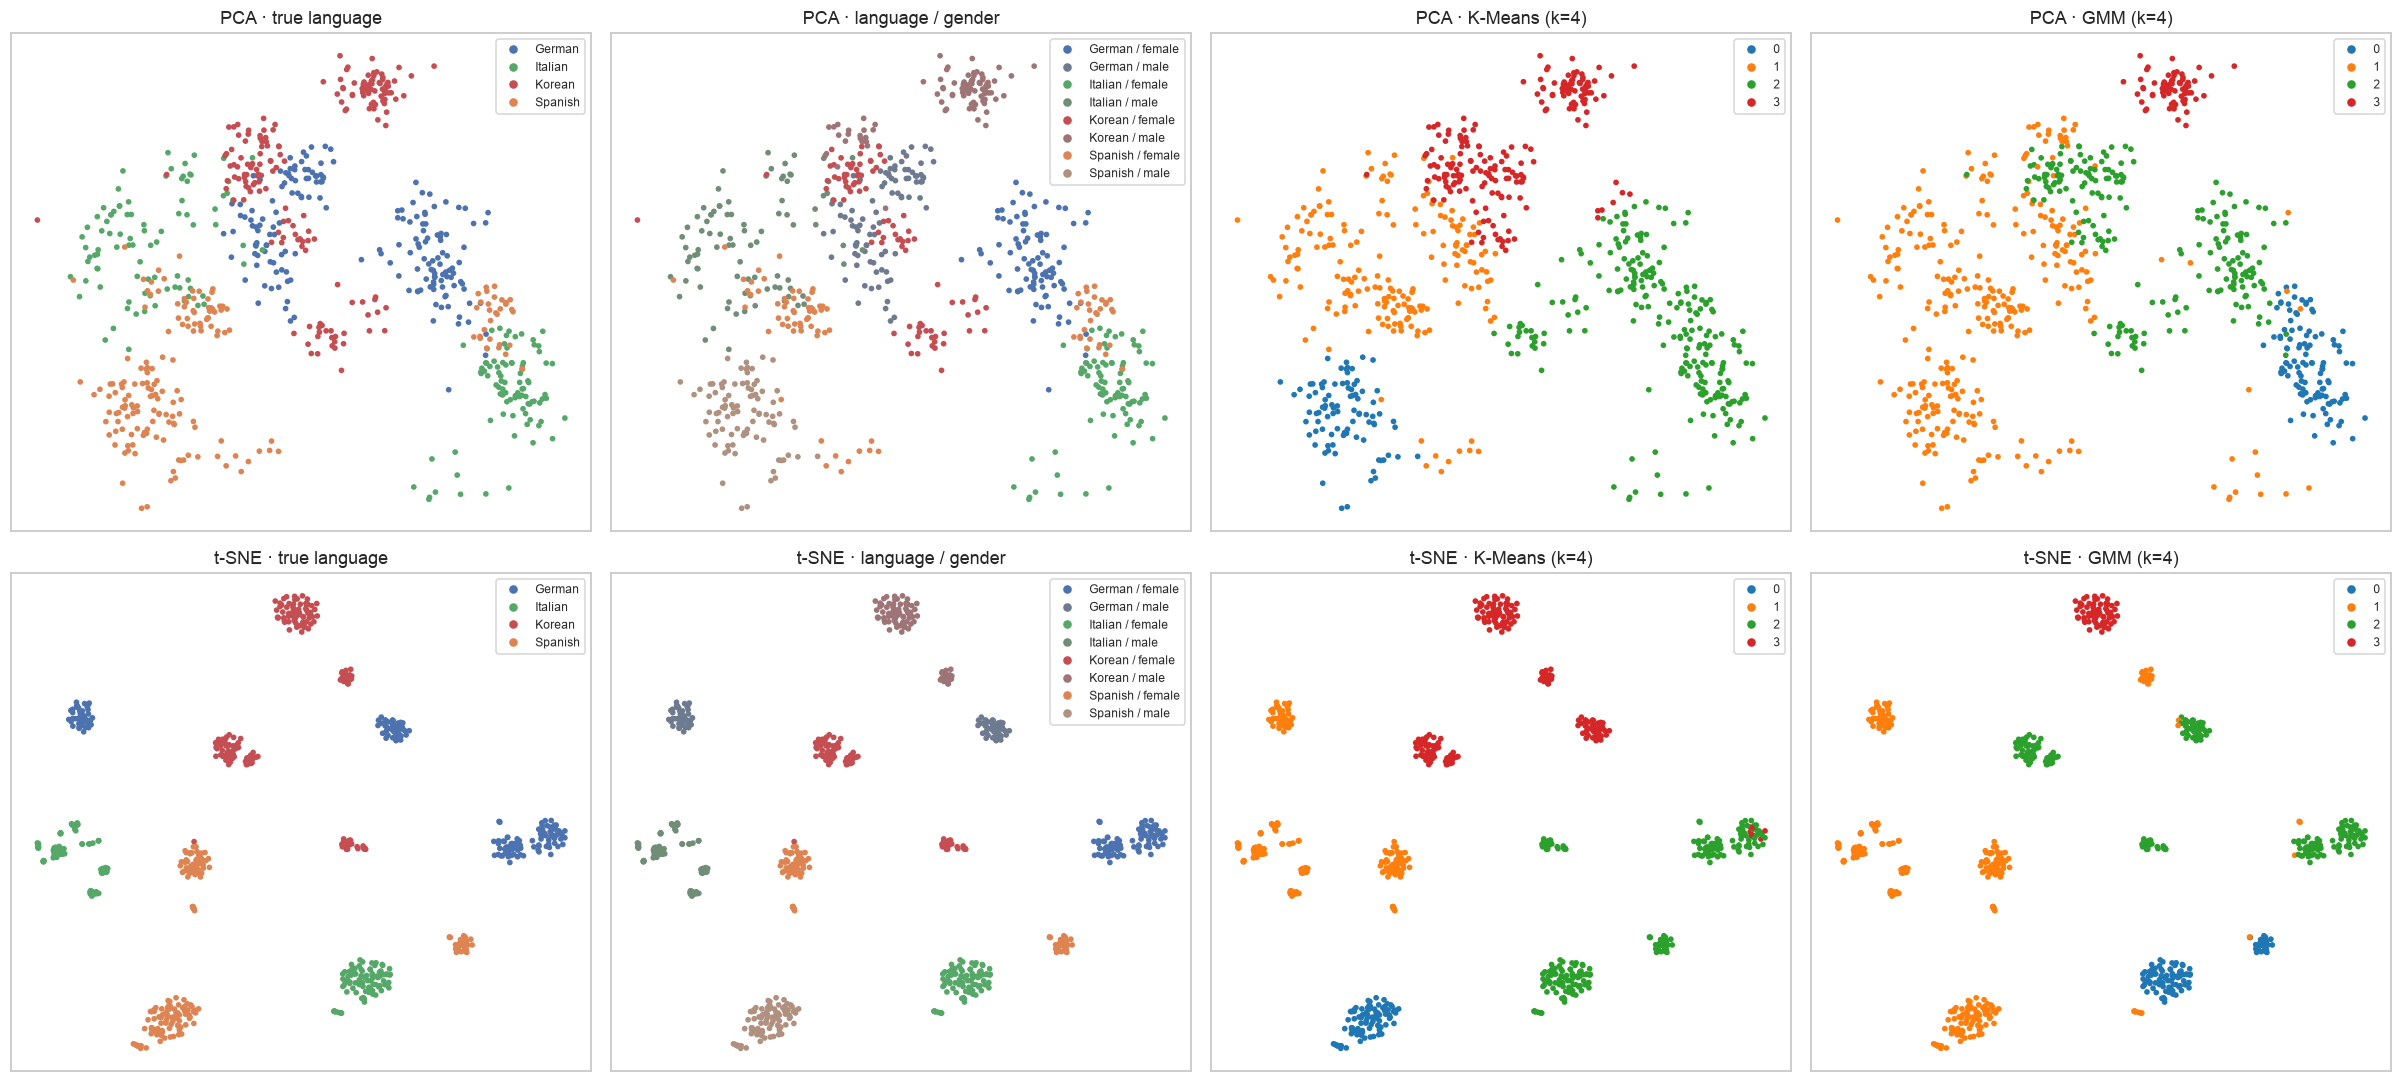

In [7]:
P2 = X[:, :2]
T2 = TSNE(n_components=2, perplexity=30, init="pca", random_state=RS).fit_transform(X)
gender_lang = (assign.language + " / " + assign.gender).to_numpy()
panels = [("true language", assign.language.to_numpy()), ("language / gender", gender_lang),
          ("K-Means (k=4)", assign["K-Means (k=4)"].to_numpy()), ("GMM (k=4)", assign["GMM (k=4)"].to_numpy())]
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for row, (emb, ename) in enumerate([(P2, "PCA"), (T2, "t-SNE")]):
    for ax, (title, lab) in zip(axes[row], panels):
        if title == "true language":
            pal = plotting.LANG_COLORS
        elif title == "language / gender":
            pal = {f"{l} / {g}": (c if g == "female" else sns.desaturate(c, 0.35)) for l, c in plotting.LANG_COLORS.items() for g in ["female", "male"]}
        else:
            pal = "tab10"; lab = lab.astype(str)
        sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=lab, palette=pal, s=14, ax=ax, linewidth=0,
                        hue_order=sorted(set(lab)) if title not in ("true language",) else C.LANGUAGES)
        ax.set_title(f"{ename} · {title}"); ax.set_xticks([]); ax.set_yticks([])
        ax.legend(fontsize=8, markerscale=1.5, loc="best")
plt.tight_layout(); plotting.save(fig, "03_embeddings")

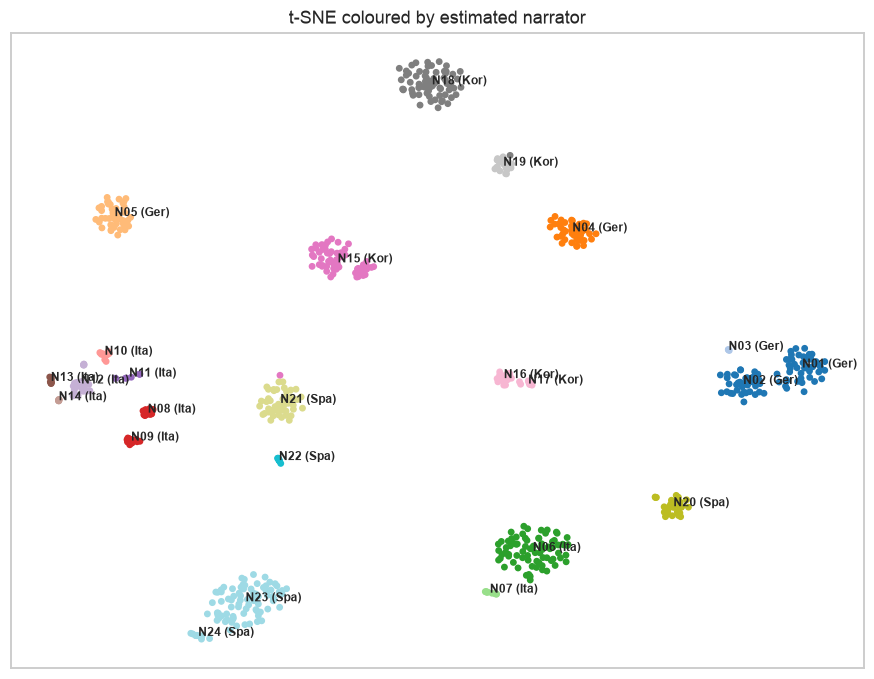

In [8]:
# t-SNE coloured by estimated narrator: are the tight islands individual voices / audiobooks?
fig, ax = plt.subplots(figsize=(10, 7.5))
codes = pd.factorize(assign.narrator, sort=True)[0]
ax.scatter(T2[:, 0], T2[:, 1], c=codes, cmap="tab20", s=12)
for n in sorted(assign.narrator.unique()):
    sel_n = (assign.narrator == n).to_numpy()
    ax.annotate(f"{n} ({assign.language[sel_n].iloc[0][:3]})", T2[sel_n].mean(0), fontsize=8, weight="bold")
ax.set_title("t-SNE coloured by estimated narrator"); ax.set_xticks([]); ax.set_yticks([])
plotting.save(fig, "03_tsne_narrators")

### What do the clusters correspond to?

* **k = 4** – language purity is only 0.58–0.60 (ARI ≈ 0.28), while gender purity is 0.81–0.83. The composition tables
  show clusters made of whole narrators: e.g. one K-Means cluster is exactly the 90 Spanish-male files, another
  combines Korean male, part of Korean female and half of German male. Clusters split by voice type, not language.
* **k = 15–16 (best silhouette)** – clusters are almost perfectly language-pure (0.99) and gender-pure (1.0), with
  narrator ARI ≈ 0.87 and NMI ≈ 0.93: **each cluster is essentially one narrator**. Language purity is high only because
  every narrator reads in one language.
* **GMM (BIC, k = 10)** and **DBSCAN** (14 clusters, 5 % noise) show the same picture (narrator NMI 0.85–0.92).
* **t-SNE** shows ~20 tight, well-separated islands, one per narrator / audiobook. Languages do not form contiguous
  regions; a language is a set of separate voice islands, and the PCA view shows the same structure less sharply.

**Conclusion:** without labels, the dominant structure in these acoustic features is narrator / recording identity,
followed by gender. Language is a weaker, secondary factor. This is the unsupervised view of the same effect that makes
the random-split classification scores look perfect.